# 题目1：金融欺诈检测

## 1、读取数据：信用卡交易测试数据.xlsx和信用卡交易训练数据.xlsx，并分别查看前5行。

In [3]:
import pandas as pd
import numpy as np

train_data = pd.read_excel('数据/信用卡交易训练数据.xlsx')
test_data = pd.read_excel('数据/信用卡交易测试数据.xlsx')

print('训练数据前5行：')
print(train_data.head())
print('\n测试数据前5行：')
print(test_data.head())

训练数据前5行：
   换设备次数  支付失败次数  换IP次数  换IP国次数   交易金额  欺诈标签
0      0      11      3       5  28836     1
1      5       6      1       4  21966     1
2      6       2      0       0  18199     1
3      5       8      2       2  24803     1
4      7      10      5       0  26277     1

测试数据前5行：
   换设备次数  支付失败次数  换IP次数  换IP国次数   交易金额  欺诈标签
0      0      11      3       5  28836     1
1      5       6      1       4  21966     1
2      6       2      0       0  18199     1
3      5       8      2       2  24803     1
4      7      10      5       0  26277     1


## 2、实现特征清洗及预处理，并基于训练样本数据进行特征值和标签值划分。

In [17]:
print('训练数据基本信息：')
print(train_data.info())
print('\n缺失值统计：')
print(train_data.isnull().sum())
print('\n标签分布：')
print(train_data['欺诈标签'].value_counts())

训练数据基本信息：
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   换设备次数   1000 non-null   int64
 1   支付失败次数  1000 non-null   int64
 2   换IP次数   1000 non-null   int64
 3   换IP国次数  1000 non-null   int64
 4   交易金额    1000 non-null   int64
 5   欺诈标签    1000 non-null   int64
dtypes: int64(6)
memory usage: 47.0 KB
None

缺失值统计：
换设备次数     0
支付失败次数    0
换IP次数     0
换IP国次数    0
交易金额      0
欺诈标签      0
dtype: int64

标签分布：
欺诈标签
0    600
1    400
Name: count, dtype: int64


In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

X = train_data.drop('欺诈标签', axis=1)
y = train_data['欺诈标签']
X_test = test_data.drop('欺诈标签', axis=1)
y_test = test_data['欺诈标签']

# 划分训练集和验证集
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 标准化
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print('训练集特征形状：', X_train.shape)
print('训练集标签形状：', y_train.shape)
print('测试集特征形状：', X_test.shape)
print('测试集标签形状：', y_test.shape)
print('\n特征名称：', X_train.columns.tolist())

[[ 0.20554551 -0.86102995 -1.53425053  0.76249762 -0.73721569]
 [-0.28677906  1.00823452  1.1827399  -0.56792353  0.20332455]
 [-1.27142819  1.63132268  0.84311609  0.09728705  0.15322559]
 ...
 [-0.28677906  0.07360229 -1.19462673 -1.2331341  -1.30929163]
 [-0.28677906  1.00823452  0.16386849  0.76249762  0.51204245]
 [-0.28677906 -1.4841181  -0.17575532  2.09291876 -1.56723356]]
训练集特征形状： (800, 5)
训练集标签形状： (800,)
测试集特征形状： (299, 5)
测试集标签形状： (299,)

特征名称： ['换设备次数', '支付失败次数', '换IP次数', '换IP国次数', '交易金额']


## 3、使用逻辑回归，随机森林2种算法对样本进行模型训练。

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

lr_model = LogisticRegression(random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)
print('逻辑回归模型训练完成')

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
print('随机森林模型训练完成')

逻辑回归模型训练完成
随机森林模型训练完成


## 4、对选择的2个算法进行参数调优，每个模型至少两组超参数。

In [7]:
from sklearn.model_selection import GridSearchCV
# 逻辑回归网格搜索 

lr_param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],  # 正则化强度
    'penalty': ['l2'],  # 正则化方式
    'solver': ['lbfgs', 'liblinear']  # 求解器
}

# 交叉验证
lr_grid = GridSearchCV(
    LogisticRegression(random_state=42, max_iter=1000),
    lr_param_grid,
    cv=5
)
lr_grid.fit(X_train_scaled, y_train)

print('逻辑回归最佳参数：', lr_grid.best_params_)

G:\人工智能\P3\P3月考\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
G:\人工智能\P3\P3月考\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
G:\人工智能\P3\P3月考\venv\Lib\site-packages\sklearn\linear_model\_logisti

逻辑回归最佳参数： {'C': 0.1, 'penalty': 'l2', 'solver': 'lbfgs'}


G:\人工智能\P3\P3月考\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
G:\人工智能\P3\P3月考\venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
G:\人工智能\P3\P3月考\venv\Lib\site-packages\sklearn\linear_model\_logisti

In [8]:
# 随机森林网格搜索 

rf_param_grid = {
    'n_estimators': [50, 100, 200], # 树数量
    'max_depth': [None, 10, 20, 30], # 树深度
    'min_samples_split': [2, 5, 10] # 节点分裂所需的最小样本数
}

# 交叉验证
rf_grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_param_grid,
    cv=5,
    n_jobs=-1 # 使用所有CPU核心
)
rf_grid.fit(X_train, y_train)

print('随机森林最佳参数：', rf_grid.best_params_)

随机森林最佳参数： {'max_depth': None, 'min_samples_split': 10, 'n_estimators': 100}


In [9]:
best_lr_model = lr_grid.best_estimator_
best_rf_model = rf_grid.best_estimator_

print('调优后的逻辑回归模型：', best_lr_model)
print('调优后的随机森林模型：', best_rf_model)

调优后的逻辑回归模型： LogisticRegression(C=0.1, max_iter=1000, penalty='l2', random_state=42)
调优后的随机森林模型： RandomForestClassifier(min_samples_split=10, random_state=42)


## 5、准确率、F1分数两种指标进行模型评估。

In [10]:
from sklearn.metrics import accuracy_score, f1_score

# 预测
lr_pred = best_lr_model.predict(X_test_scaled)
rf_pred = best_rf_model.predict(X_test)

# 逻辑回归评估
lr_accuracy  = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred)
# 随机森林评估
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)

print('='*50)
print('逻辑回归模型评估：')
print(f'准确率: {lr_accuracy}')
print(f'F1分数: {lr_f1}')

print('='*50)
print('随机森林模型评估：')
print(f'准确率: {rf_accuracy}')
print(f'F1分数: {rf_f1}')

逻辑回归模型评估：
准确率: 0.5986622073578596
F1分数: 0.7489539748953975
随机森林模型评估：
准确率: 0.7625418060200669
F1分数: 0.8652751423149905


## 6、分别绘制两个模型的ROC曲线来评估模型预测的效果。

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 设置中文显示，防止图表中文乱码
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用黑体显示中文
plt.rcParams['axes.unicode_minus'] = False    # 正常显示负号

# 获取模型预测概率
lr_proba = best_lr_model.predict_proba(X_val_scaled)[:, 1]  # 逻辑回归预测概率
rf_proba = best_rf_model.predict_proba(X_val)[:, 1]        # 随机森林预测概率


# 逻辑回归的FPR、TPR和AUC值
lr_fpr, lr_tpr, lr_ = roc_curve(y_val, lr_proba)
lr_auc = auc(lr_fpr, lr_tpr)                    

# 随机森林的FPR、TPR和AUC值
rf_fpr, rf_tpr, rf_ = roc_curve(y_val, rf_proba)
rf_auc = auc(rf_fpr, rf_tpr)                    

print(f'逻辑回归 AUC = {lr_auc}')
print(f'随机森林 AUC = {rf_auc}')

逻辑回归 AUC = 0.8426041666666667
随机森林 AUC = 0.8360416666666667


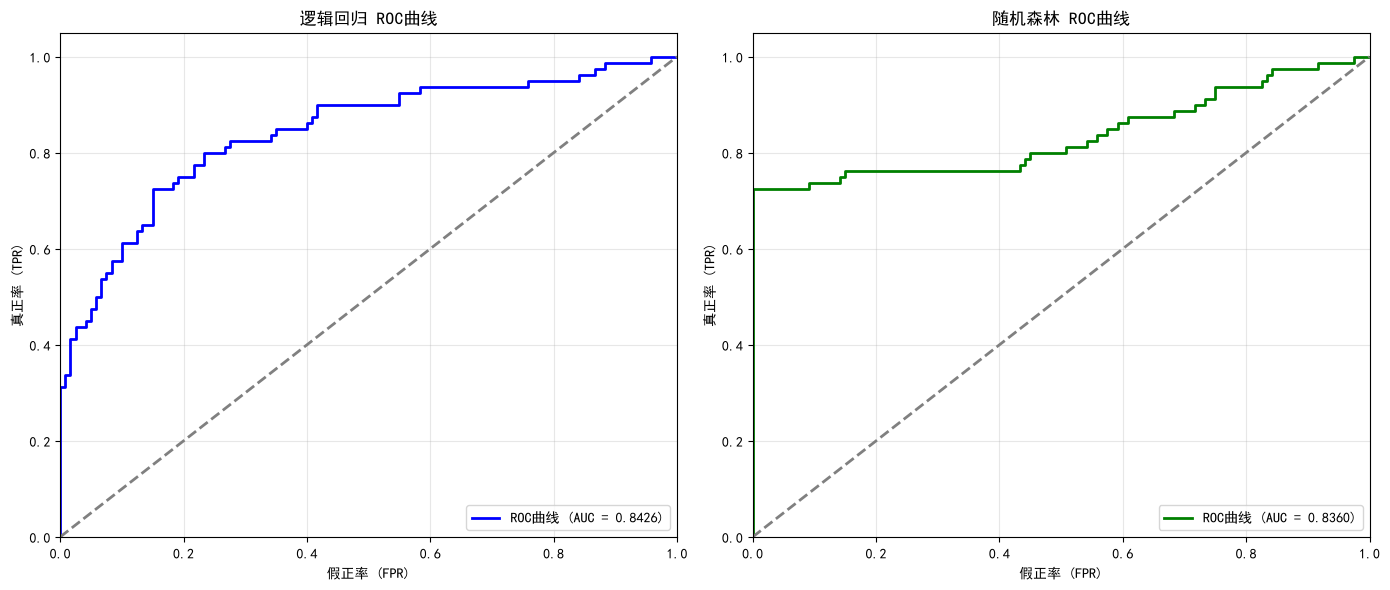

In [12]:
# 创建1行2列的画布
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# 逻辑回归ROC曲线
ax1.plot(lr_fpr, lr_tpr, color='blue', lw=2, label=f'ROC曲线 (AUC = {lr_auc:.4f})')
ax1.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
ax1.set_xlim([0.0, 1.0])       # x轴范围
ax1.set_ylim([0.0, 1.05])      # y轴范围
ax1.set_xlabel('假正率 (FPR)')  # x轴标签
ax1.set_ylabel('真正率 (TPR)')  # y轴标签
ax1.set_title('逻辑回归 ROC曲线')  # 标题
ax1.legend(loc='lower right')  # 图例放在右下角
ax1.grid(True, alpha=0.3)      # 显示网格，透明度0.3

# 随机森林ROC曲线
ax2.plot(rf_fpr, rf_tpr, color='green', lw=2, label=f'ROC曲线 (AUC = {rf_auc:.4f})')
ax2.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('假正率 (FPR)')
ax2.set_ylabel('真正率 (TPR)')
ax2.set_title('随机森林 ROC曲线')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()  # 自动调整子图间距，防止文字重叠
plt.show()          # 显示图片

## 7、分别输出预测结果，特征重要性或者斜率截距系数。

In [13]:
print('逻辑回归预测结果（前20条）：')
print('='*60)
lr_results = pd.DataFrame({
    '真实标签': y_test.values[:20],
    '预测标签': lr_pred[:20],
    '预测为欺诈概率': lr_proba[:20].round(4)
})
print(lr_results)
print(f'\n总预测样本数: {len(y_test)}')
print(f'预测正确数: {sum(y_test.values == lr_pred)}')
print(f'预测错误数: {sum(y_test.values != lr_pred)}')

逻辑回归预测结果（前20条）：
    真实标签  预测标签  预测为欺诈概率
0      1     1   0.3729
1      1     1   0.7375
2      1     0   0.9548
3      1     1   0.1116
4      1     1   0.1145
5      1     0   0.1946
6      1     1   0.5112
7      1     0   0.6025
8      1     0   0.2253
9      1     1   0.2070
10     1     1   0.1887
11     1     0   0.4340
12     1     1   0.5568
13     1     1   0.9324
14     1     1   0.4866
15     1     1   0.0845
16     1     0   0.1601
17     1     1   0.5717
18     1     1   0.3309
19     1     1   0.7002

总预测样本数: 299
预测正确数: 179
预测错误数: 120


In [14]:
print('逻辑回归 - 斜率系数和截距：')
print('='*60)
feature_names = X_train.columns.tolist() # 特征名字
lr_coefficients = pd.DataFrame({
    '特征': feature_names,
    '斜率系数': best_lr_model.coef_[0]
})
lr_coefficients = lr_coefficients.sort_values('斜率系数', key=abs, ascending=False).reset_index(drop=True)
print(lr_coefficients)
print(f'\n截距 (Intercept): {best_lr_model.intercept_[0]:.4f}')

逻辑回归 - 斜率系数和截距：
       特征      斜率系数
0   换设备次数  0.826571
1  换IP国次数  0.816840
2  支付失败次数  0.503807
3   换IP次数  0.201483
4    交易金额 -0.069198

截距 (Intercept): -0.4910


In [15]:
print('随机森林预测结果（前20条）：')
print('='*60)
rf_results = pd.DataFrame({
    '真实标签': y_test.values[:20],
    '预测标签': rf_pred[:20],
    '预测为欺诈概率': rf_proba[:20]
})
print(rf_results)
print(f'\n总预测样本数: {len(y_test)}')
print(f'预测正确数: {sum(y_test.values == rf_pred)}')
print(f'预测错误数: {sum(y_test.values != rf_pred)}')

随机森林预测结果（前20条）：
    真实标签  预测标签   预测为欺诈概率
0      1     1  0.218942
1      1     1  1.000000
2      1     1  1.000000
3      1     1  0.075117
4      1     1  0.174852
5      1     1  0.323860
6      1     0  0.072425
7      1     1  0.998333
8      1     1  0.111036
9      1     1  0.361361
10     1     1  0.386861
11     1     0  0.075221
12     1     1  0.235381
13     1     1  1.000000
14     1     1  0.998333
15     1     1  0.164035
16     1     1  0.124588
17     1     1  0.190040
18     1     1  0.270065
19     1     1  0.980000

总预测样本数: 299
预测正确数: 228
预测错误数: 71


In [16]:
print('随机森林 - 特征重要性：')
print('='*60)
rf_importance = pd.DataFrame({
    '特征': feature_names,
    '重要性': best_rf_model.feature_importances_
})
rf_importance = rf_importance.sort_values('重要性', ascending=False).reset_index(drop=True)
print(rf_importance)

随机森林 - 特征重要性：
       特征       重要性
0   换设备次数  0.305925
1  换IP国次数  0.276961
2  支付失败次数  0.212747
3   换IP次数  0.113074
4    交易金额  0.091293
